# time
section on time cost (where `lam_breadth = 0.0` and `lam_depth = 0.0`)



In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import nn_bowl
import pandas as pd
import numpy as np
from scipy.stats import t
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [3]:
TICK_VALS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
TICK_TEXT = ["0", ".1", ".2", ".3", ".4", ".5", ".6", ".7", ".8", ".9", "1"]
CIFAR10_CATEGORIES = nn_bowl.utils.get_cifar_labels()
cfg_base = nn_bowl.utils.load_config("config_time_selection.yaml")
WIDTH = cfg_base.plotting.width.full
nn_bowl.utils.set_plotly_template(cfg_base)
figures_dir = nn_bowl.paths.FIGURES_DIR / "time"

In [4]:
# ensuring that all evaluation files exist for all combinations of lam_depth, lam_breadth, lam_time and instance
# nn_bowl.utils.ensure_evaluation_files_exist(cfg_base, skip_pruning=False)

In [5]:
# model df
model_df = nn_bowl.utils.get_model_df(cfg_base)
model_df["lam_time"] = model_df["costs.time.lam"]
model_df

  0%|          | 0/220 [00:00<?, ?it/s]

Labels shape for cifar10: (10000,)


100%|██████████| 220/220 [00:34<00:00,  6.43it/s]


,model_name,model.time_selection.scheme,costs.time.lam,instance,cost_depth,cost_breadth,cost_time,accuracy,lam_time
0,scheme=fixed_lam=0.0_i0,fixed,0.0,0,0.131076,0.137376,1.223641,0.8677,0.0
1,scheme=fixed_lam=0.1_i0,fixed,0.1,0,0.129640,0.136876,1.222455,0.8843,0.1
2,scheme=fixed_lam=0.2_i0,fixed,0.2,0,0.145877,0.146681,0.752308,0.8784,0.2
3,scheme=fixed_lam=0.3_i0,fixed,0.3,0,0.140917,0.141641,0.749545,0.8753,0.3
4,scheme=fixed_lam=0.4_i0,fixed,0.4,0,0.149875,0.141343,0.511691,0.8674,0.4
...,...,...,...,...,...,...,...,...,...
215,scheme=adaptive_lam=0.6_i9,adaptive,0.6,9,0.141849,0.138590,0.450226,0.8685,0.6
216,scheme=adaptive_lam=0.7_i9,adaptive,0.7,9,0.142724,0.136611,0.444707,0.8652,0.7
217,scheme=adaptive_lam=0.8_i9,adaptive,0.8,9,0.155235,0.134832,0.276070,0.8549,0.8
218,scheme=adaptive_lam=0.9_i9,adaptive,0.9,9,0.150416,0.133526,0.275944,0.8560,0.9


In [6]:
fig = make_subplots(rows=1, cols=1, horizontal_spacing=0.2)
fig.update_layout(
    width=WIDTH * 0.2,
    height=WIDTH * 0.25
)
fig.update_layout(margin=dict(l=45, r=10, t=20, b=60))

for i, cost_name in enumerate(["time"]):
    x_col = f"lam_{cost_name}"
    y_col = f"cost_{cost_name}"

    for scheme in ["adaptive", "fixed"]:
        scheme_df = model_df[model_df["model.time_selection.scheme"] == scheme]
        grouped = scheme_df.groupby(x_col)[y_col].apply(
            lambda x: pd.Series({
                "mean": np.mean(x),
                "std": np.std(x, ddof=1),
            })
        ).unstack().reset_index()

        y_vals = grouped["mean"]
        multiplier = t.ppf(0.975, df=cfg_base.experiment.n_instances - 1)
        y_upper = multiplier * grouped["std"] / np.sqrt(cfg_base.experiment.n_instances)
        y_lower = y_upper

        style = "dash" if scheme == "fixed" else "solid"
        marker_symbol = "x" if scheme == "fixed" else "circle"
        color = cfg_base.plotting[cost_name] if scheme == "adaptive" else cfg_base.plotting.fixed_time

        fig.add_trace(
            go.Scatter(
                x=grouped[x_col],
                y=y_vals,
                error_y=dict(
                    type="data",
                    symmetric=False,
                    array=y_upper,
                    arrayminus=y_lower,
                    visible=True,
                ),
                mode="lines+markers",
                name=scheme,
                marker=dict(color=color, symbol=marker_symbol),
                line=dict(color=color, dash=style),
            ),
            row=1, col=i+1
        )

    fig.update_xaxes(title_text=f"λ<sub>{cost_name}</sub>", row=1, col=i+1)
    fig.update_yaxes(title_text=f"ℒ<sub>{cost_name}</sub>", row=1, col=i+1, title_standoff=7)

fig.update_xaxes(
    tickmode="array",
    tickvals=[0.0, 0.5, 1.0],
    tickangle=0,
    zeroline=False,
    title_standoff=5,
)
fig.update_layout(
    showlegend=True,
    legend=dict(
        title=dict(text="time selection", font=dict(size=13)),
        x=0.9, y=0.95,
        font=dict(size=13),
        xanchor='center', yanchor='top',
    ),
)

fig.show()
nn_bowl.utils.save_figure(fig, figures_dir, "time_lambdas_costs_ci", scale=2)

In [7]:
time_df = nn_bowl.utils.get_time_df(cfg_base, model_df)
time_df

100%|██████████| 220/220 [00:17<00:00, 12.28it/s]


,model_name,model.time_selection.scheme,costs.time.lam,instance,dataset_idx,t,t_weight,str_lam_time
0,scheme=fixed_lam=0.0_i0,fixed,0.0,0,0,0,0.008065,lam_time=0.0
1,scheme=fixed_lam=0.0_i0,fixed,0.0,0,0,1,0.008854,lam_time=0.0
2,scheme=fixed_lam=0.0_i0,fixed,0.0,0,0,2,0.012558,lam_time=0.0
3,scheme=fixed_lam=0.0_i0,fixed,0.0,0,0,3,0.021496,lam_time=0.0
4,scheme=fixed_lam=0.0_i0,fixed,0.0,0,0,4,0.949027,lam_time=0.0
...,...,...,...,...,...,...,...,...
10999995,scheme=adaptive_lam=1.0_i9,adaptive,1.0,9,9999,0,0.953580,lam_time=1.0
10999996,scheme=adaptive_lam=1.0_i9,adaptive,1.0,9,9999,1,0.016142,lam_time=1.0
10999997,scheme=adaptive_lam=1.0_i9,adaptive,1.0,9,9999,2,0.011944,lam_time=1.0
10999998,scheme=adaptive_lam=1.0_i9,adaptive,1.0,9,9999,3,0.009923,lam_time=1.0


In [8]:
image_df = nn_bowl.utils.get_image_df(cfg_base, model_df)
image_df

100%|██████████| 220/220 [00:17<00:00, 12.89it/s]


,model_name,model.time_selection.scheme,costs.time.lam,instance,dataset_idx,label,pred,correct,confidence,entropy,prob_0,prob_1,prob_2,prob_3,prob_4,prob_5,prob_6,prob_7,prob_8,prob_9
0,scheme=fixed_lam=0.0_i0,fixed,0.0,0,0,3,3,1,0.978639,0.142608,8.343788e-04,1.099879e-03,0.003550,9.786391e-01,0.001107,8.735280e-03,1.572074e-03,0.001546,1.833118e-03,1.082804e-03
1,scheme=fixed_lam=0.0_i0,fixed,0.0,0,1,8,8,1,0.954556,0.218538,5.109640e-03,3.688412e-02,0.000961,1.909068e-04,0.000461,2.022290e-04,9.682403e-04,0.000107,9.545559e-01,5.593029e-04
2,scheme=fixed_lam=0.0_i0,fixed,0.0,0,2,8,8,1,0.990724,0.070694,1.419734e-03,2.672582e-03,0.000656,5.613500e-04,0.000426,3.556797e-04,1.130642e-03,0.000267,9.907239e-01,1.786444e-03
3,scheme=fixed_lam=0.0_i0,fixed,0.0,0,3,0,8,0,0.026557,0.178455,2.655687e-02,8.059231e-04,0.001209,1.080755e-03,0.000645,6.689230e-04,5.087678e-04,0.000205,9.663058e-01,2.013831e-03
4,scheme=fixed_lam=0.0_i0,fixed,0.0,0,4,6,6,1,0.987560,0.089113,2.256305e-04,3.898149e-04,0.001346,4.649129e-03,0.002190,2.111284e-03,9.875603e-01,0.000599,2.941565e-04,6.351042e-04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2199995,scheme=adaptive_lam=1.0_i9,adaptive,1.0,9,9995,8,0,0,0.323268,0.729739,6.611951e-01,4.516771e-03,0.000359,3.589477e-03,0.000092,3.060691e-04,1.792632e-03,0.001541,3.232676e-01,3.339161e-03
2199996,scheme=adaptive_lam=1.0_i9,adaptive,1.0,9,9996,3,3,1,0.502160,0.794423,2.251797e-07,5.366800e-08,0.000100,5.021598e-01,0.005909,4.767400e-01,1.443047e-04,0.014945,1.205937e-07,6.625567e-07
2199997,scheme=adaptive_lam=1.0_i9,adaptive,1.0,9,9997,5,5,1,0.997154,0.022239,3.013501e-08,1.838578e-09,0.000108,1.377279e-03,0.000047,9.971538e-01,3.247253e-05,0.001282,4.678258e-08,1.313564e-08
2199998,scheme=adaptive_lam=1.0_i9,adaptive,1.0,9,9998,1,1,1,0.983087,0.101543,1.245266e-02,9.830868e-01,0.002687,6.039207e-04,0.000124,2.850848e-04,3.144224e-04,0.000032,2.994818e-04,1.148440e-04


In [9]:
def get_time_used(row):
    time_used = 0.0
    n_timesteps = len([c for c in row.index if c.startswith("t_")])
    for t in range(n_timesteps):
        time_used += row[f"t_{t}"] * (t + 1)
    return time_used

time_used_df = time_df.pivot_table(
    index=[c for c in time_df.columns if c not in ("t", "t_weight")],
    columns="t",
    values="t_weight",
).reset_index()

time_used_df.columns = [f"t_{c}" if isinstance(c, (int, np.integer)) else c for c in time_used_df.columns]
time_used_df["time_used"] = time_used_df.apply(get_time_used, axis=1)

time_used_df["time_used_bin"] = pd.cut(time_used_df["time_used"], bins=5)
time_used_df["time_used_bin"] = time_used_df["time_used_bin"].apply(lambda x: x.mid)


# add correct col from image df
time_used_df = time_used_df.merge(
    image_df[["model_name", "instance", "dataset_idx", "correct"]],
    on=["model_name", "instance", "dataset_idx"],
)
time_used_df

,model_name,model.time_selection.scheme,costs.time.lam,instance,dataset_idx,str_lam_time,t_0,t_1,t_2,t_3,t_4,time_used,time_used_bin,correct
0,scheme=adaptive_lam=0.0_i0,adaptive,0.0,0,0,lam_time=0.0,0.009226,0.009063,0.010966,0.018977,0.951768,4.894998,4.5175,1
1,scheme=adaptive_lam=0.0_i0,adaptive,0.0,0,1,lam_time=0.0,0.006761,0.009103,0.016004,0.024876,0.943257,4.888764,4.5175,1
2,scheme=adaptive_lam=0.0_i0,adaptive,0.0,0,2,lam_time=0.0,0.007351,0.008163,0.015419,0.031952,0.937115,4.883316,4.5175,1
3,scheme=adaptive_lam=0.0_i0,adaptive,0.0,0,3,lam_time=0.0,0.007254,0.008714,0.015943,0.031672,0.936417,4.881284,4.5175,0
4,scheme=adaptive_lam=0.0_i0,adaptive,0.0,0,4,lam_time=0.0,0.007008,0.008396,0.016512,0.033175,0.934909,4.880581,4.5175,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2199995,scheme=fixed_lam=1.0_i9,fixed,1.0,9,9995,lam_time=1.0,0.952886,0.016901,0.012277,0.009748,0.008188,1.103451,1.4810,0
2199996,scheme=fixed_lam=1.0_i9,fixed,1.0,9,9996,lam_time=1.0,0.952886,0.016901,0.012277,0.009748,0.008188,1.103451,1.4810,1
2199997,scheme=fixed_lam=1.0_i9,fixed,1.0,9,9997,lam_time=1.0,0.952886,0.016901,0.012277,0.009748,0.008188,1.103451,1.4810,1
2199998,scheme=fixed_lam=1.0_i9,fixed,1.0,9,9998,lam_time=1.0,0.952886,0.016901,0.012277,0.009748,0.008188,1.103451,1.4810,1


In [10]:
run_agg_df = time_used_df.groupby(
    ["costs.time.lam", "model.time_selection.scheme", "instance"],
    as_index=False,
).agg(
    correct_mean=("correct", "mean"),
    time_used_mean=("time_used", "mean"),
)



In [11]:
import numpy as np
import plotly.graph_objects as go
from scipy.optimize import curve_fit


sel = run_agg_df["costs.time.lam"] > 0.0
time_used = np.array(run_agg_df[sel]["time_used_mean"])
correct = np.array(run_agg_df[sel]["correct_mean"])
scheme = np.array(run_agg_df[sel]["model.time_selection.scheme"])

def log_func(t, a, b):
    return a * np.log(t) + b

colors = {
    'adaptive': cfg_base.plotting.time,
    'fixed': cfg_base.plotting.fixed_time,
}

n_bootstrap = 1000
ci_level = 0.95

fig = go.Figure()

for s in ['adaptive', 'fixed']:
    mask = scheme == s
    x = time_used[mask]
    y = correct[mask]

    # Fit on original data
    popt, _ = curve_fit(log_func, x, y)
    t_smooth = np.linspace(x.min(), x.max(), 100)
    y_smooth = log_func(t_smooth, *popt)

    # Bootstrap CI
    n_pts = len(x)
    boot_curves = np.zeros((n_bootstrap, len(t_smooth)))
    for b in range(n_bootstrap):
        idx = np.random.choice(n_pts, size=n_pts, replace=True)
        try:
            popt_b, _ = curve_fit(log_func, x[idx], y[idx])
            boot_curves[b] = log_func(t_smooth, *popt_b)
        except RuntimeError:
            boot_curves[b] = np.nan

    alpha = (1 - ci_level) / 2
    lower = np.nanpercentile(boot_curves, 100 * alpha, axis=0)
    upper = np.nanpercentile(boot_curves, 100 * (1 - alpha), axis=0)

    # Shaded CI region
    fig.add_trace(go.Scatter(
        x=np.concatenate([t_smooth, t_smooth[::-1]]),
        y=np.concatenate([upper, lower[::-1]]),
        fill='toself',
        fillcolor=colors[s].replace(')', ', 0.2)').replace('rgb(', 'rgba(') if 'rgb(' in colors[s] else colors[s],
        line=dict(width=0),
        showlegend=False,
        hoverinfo='skip',
        opacity=0.3,
    ))

    # Fit line
    style = 'dash' if s != 'adaptive' else 'solid'
    fig.add_trace(go.Scatter(
        x=t_smooth, y=y_smooth, mode='lines',
        name=f'{s}',
        line=dict(color=colors[s], dash=style, width=3),
    ))

    marker_symbol = 'x' if s == 'fixed' else 'circle'
    # Data points
    fig.add_trace(go.Scatter(
        x=x, y=y, mode='markers', name=None,
        marker=dict(color=colors[s], size=4, symbol=marker_symbol),
        showlegend=False,
    ))

fig.update_layout(xaxis_title='time used', yaxis_title='accuracy')
fig.update_layout(
    yaxis=dict(range=[0.842, 0.886]),
    showlegend=True,
    legend=dict(
        # title="time selection",
        title=dict(text="time selection", font=dict(size=13)),
        x=0.9, y=0.05,
        font=dict(size=13),
        xanchor='center', yanchor='bottom',
        # bgcolor='rgba(0,0,0,0)',
    ))
fig.update_yaxes(title_standoff=12,
                 tickvals=[0.85, 0.86, 0.87, 0.88],)
fig.update_xaxes(title_standoff=8)
fig.update_layout(margin=dict(l=55, r=0, t=0, b=60))
fig.update_layout(width=WIDTH * 0.25, height=WIDTH * 0.25)
fig.show()
nn_bowl.utils.save_figure(fig, figures_dir, "time_used_vs_accuracy_adaptive_fixed_fit", scale=2)

In [12]:
run_agg_df

,costs.time.lam,model.time_selection.scheme,instance,correct_mean,time_used_mean
0,0.0,adaptive,0,0.8770,4.889800
1,0.0,adaptive,1,0.8810,4.888040
2,0.0,adaptive,2,0.8747,4.885939
3,0.0,adaptive,3,0.8546,4.887979
4,0.0,adaptive,4,0.8685,4.887728
...,...,...,...,...,...
215,1.0,fixed,5,0.8567,1.103443
216,1.0,fixed,6,0.8519,1.103451
217,1.0,fixed,7,0.8489,1.103439
218,1.0,fixed,8,0.8549,1.103457


In [13]:
# lambda vs. time used
fig = make_subplots(rows=1, cols=1, horizontal_spacing=0.2)
fig.update_layout(height=WIDTH * 0.25, width=WIDTH * 0.2)
fig.update_layout(margin=dict(l=45, r=10, t=20, b=60))

for scheme in ["adaptive", "fixed"]:
    scheme_df = run_agg_df[run_agg_df["model.time_selection.scheme"] == scheme]
    grouped = scheme_df.groupby("costs.time.lam")["time_used_mean"].agg(["mean", "std"]).reset_index()

    x_col = "costs.time.lam"
    n = cfg_base.experiment.n_instances
    multiplier = t.ppf(0.975, df=n - 1)

    style = "dash" if scheme == "fixed" else "solid"
    marker_symbol = "x" if scheme == "fixed" else "circle"
    color = cfg_base.plotting.time if scheme == "adaptive" else cfg_base.plotting.fixed_time

    fig.add_trace(
        go.Scatter(
            x=grouped[x_col],
            y=grouped["mean"],
            error_y=dict(
                type="data",
                array=multiplier * grouped["std"] / np.sqrt(n),
                visible=True,
            ),
            mode="lines+markers",
            name=scheme,
            marker=dict(color=color, symbol=marker_symbol, size=7, opacity=1.0),
            line=dict(color=color, dash=style),
        ),
        row=1, col=1
    )

fig.update_xaxes(title_text="λ<sub>time</sub>", row=1, col=1)
fig.update_yaxes(title_text="time used", row=1, col=1, title_standoff=7)
fig.update_xaxes(
    tickmode="array",
    tickvals=[0.0, 0.5, 1.0],
    tickangle=0,
    title_standoff=5,
)
fig.show()
nn_bowl.utils.save_figure(fig, figures_dir, "lambda_time_used", scale=2)

In [14]:
time_used_df

,model_name,model.time_selection.scheme,costs.time.lam,instance,dataset_idx,str_lam_time,t_0,t_1,t_2,t_3,t_4,time_used,time_used_bin,correct
0,scheme=adaptive_lam=0.0_i0,adaptive,0.0,0,0,lam_time=0.0,0.009226,0.009063,0.010966,0.018977,0.951768,4.894998,4.5175,1
1,scheme=adaptive_lam=0.0_i0,adaptive,0.0,0,1,lam_time=0.0,0.006761,0.009103,0.016004,0.024876,0.943257,4.888764,4.5175,1
2,scheme=adaptive_lam=0.0_i0,adaptive,0.0,0,2,lam_time=0.0,0.007351,0.008163,0.015419,0.031952,0.937115,4.883316,4.5175,1
3,scheme=adaptive_lam=0.0_i0,adaptive,0.0,0,3,lam_time=0.0,0.007254,0.008714,0.015943,0.031672,0.936417,4.881284,4.5175,0
4,scheme=adaptive_lam=0.0_i0,adaptive,0.0,0,4,lam_time=0.0,0.007008,0.008396,0.016512,0.033175,0.934909,4.880581,4.5175,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2199995,scheme=fixed_lam=1.0_i9,fixed,1.0,9,9995,lam_time=1.0,0.952886,0.016901,0.012277,0.009748,0.008188,1.103451,1.4810,0
2199996,scheme=fixed_lam=1.0_i9,fixed,1.0,9,9996,lam_time=1.0,0.952886,0.016901,0.012277,0.009748,0.008188,1.103451,1.4810,1
2199997,scheme=fixed_lam=1.0_i9,fixed,1.0,9,9997,lam_time=1.0,0.952886,0.016901,0.012277,0.009748,0.008188,1.103451,1.4810,1
2199998,scheme=fixed_lam=1.0_i9,fixed,1.0,9,9998,lam_time=1.0,0.952886,0.016901,0.012277,0.009748,0.008188,1.103451,1.4810,1


In [15]:

keys = ["model_name", "instance", "dataset_idx"]

sel = (
    (time_used_df["model.time_selection.scheme"] == "adaptive")
    & (time_used_df["costs.time.lam"] > 0.0)
)

difficulty_df = (
    time_used_df.loc[sel, keys + ["costs.time.lam", "correct", "time_used"]]
    .merge(
        image_df[keys + ["entropy", "confidence", "label"]],
        on=keys, how="left", validate="one_to_one",
    )
    .rename(columns={"costs.time.lam": "lam_time"})
)
difficulty_df["cifar10_category"] = difficulty_df["label"].map(lambda x: CIFAR10_CATEGORIES[x])
difficulty_df = difficulty_df.drop(columns="label")

# sanity checks: 10 lambdas x 10 seeds x 10k images, no failed joins
assert len(difficulty_df) == 100 * 10_000
assert difficulty_df[["entropy", "confidence"]].notna().all().all()
difficulty_df


,model_name,instance,dataset_idx,lam_time,correct,time_used,entropy,confidence,cifar10_category
0,scheme=adaptive_lam=0.1_i0,0,0,0.1,1,4.862428,0.142379,0.975993,cat
1,scheme=adaptive_lam=0.1_i0,0,1,0.1,1,3.590045,0.317500,0.910433,ship
2,scheme=adaptive_lam=0.1_i0,0,2,0.1,1,3.113243,0.062385,0.991704,ship
3,scheme=adaptive_lam=0.1_i0,0,3,0.1,1,4.707525,0.472156,0.845558,airplane
4,scheme=adaptive_lam=0.1_i0,0,4,0.1,1,2.956334,0.063539,0.991432,frog
...,...,...,...,...,...,...,...,...,...
999995,scheme=adaptive_lam=1.0_i9,9,9995,1.0,0,1.103481,0.729739,0.323268,ship
999996,scheme=adaptive_lam=1.0_i9,9,9996,1.0,1,1.103496,0.794423,0.502160,cat
999997,scheme=adaptive_lam=1.0_i9,9,9997,1.0,1,1.103468,0.022239,0.997154,dog
999998,scheme=adaptive_lam=1.0_i9,9,9998,1.0,1,1.103495,0.101543,0.983087,automobile


In [16]:
# CIFAR-10H raw trials + helpers for per-image human measures
human_raw_df = pd.read_csv(nn_bowl.paths.DATA_DIR / "cifar10h" / "cifar10h-raw.csv")

IDX_COL = "cifar10_test_test_idx"   # -1 for attention-check trials
RT_COL = "reaction_time"
CHOSEN_COL = "chosen_label"
TRUE_COL = "true_label"


def _align(series_x, series_y):
    """Align two indexed Series on their shared index, dropping NaNs."""
    common = series_x.index.intersection(series_y.index)
    x = series_x.reindex(common).values
    y = series_y.reindex(common).values
    m = ~np.isnan(x) & ~np.isnan(y)
    return x[m], y[m]


def human_entropy_per_image(human_raw_df, n_classes=10):
    """Shannon entropy (nats) of the response distribution across annotators.
    Higher = more disagreement = harder. This is the Fig. 4h variable."""
    attn = human_raw_df[IDX_COL] >= 0
    sub = human_raw_df[attn]
    counts = (sub.groupby([IDX_COL, CHOSEN_COL]).size()
                 .unstack(fill_value=0)
                 .reindex(columns=range(n_classes), fill_value=0))
    p = counts.div(counts.sum(axis=1), axis=0).values
    with np.errstate(divide="ignore", invalid="ignore"):
        logp = np.where(p > 0, np.log(p), 0.0)
    return pd.Series(-(p * logp).sum(axis=1), index=counts.index)

In [17]:
# human entropy per image from raw CIFAR-10H trials (attention checks excluded)
human_ent = human_entropy_per_image(human_raw_df)
human_df = human_ent.rename("entropy").rename_axis("dataset_idx").reset_index()

# get category mapping from difficulty_df (one per dataset_idx)
category_map = difficulty_df[["dataset_idx", "cifar10_category"]].drop_duplicates("dataset_idx")
human_df = human_df.merge(category_map, on="dataset_idx", validate="one_to_one")

# diagnostic: compare against entropy from the released cifar10h-probs.npy
human_probs = np.load(nn_bowl.paths.DATA_DIR / "cifar10h" / "cifar10h-probs.npy")
ent_probs = pd.Series(-np.sum(human_probs * np.log(human_probs + 1e-12), axis=1))
a, b = _align(human_ent, ent_probs)
print(f"raw vs probs entropy: r = {np.corrcoef(a, b)[0, 1]:.4f}, max |diff| = {np.abs(a - b).max():.4f}, "
      f"n differing = {(np.abs(a - b) > 1e-6).sum()} / {len(a)}")
human_df

raw vs probs entropy: r = 0.9866, max |diff| = 0.2797, n differing = 2369 / 10000


,dataset_idx,entropy,cifar10_category
0,0,0.288342,cat
1,1,0.189683,ship
2,2,-0.000000,ship
3,3,0.868098,airplane
4,4,0.096509,frog
...,...,...,...
9995,9995,0.575228,ship
9996,9996,0.158411,cat
9997,9997,0.361947,dog
9998,9998,0.165443,automobile


In [18]:
human_raw_df

,annotator_id,trial_index,is_attn_check,true_category,chosen_category,true_label,chosen_label,correct_guess,cifar10_test_test_idx,image_filename,subcategory,reaction_time,time_elapsed
0,0,0,0,ship,ship,8,8,1,6798,cabin_cruiser_s_000814.png,cabin_cruiser,1342,1342
1,0,1,0,deer,horse,4,7,0,1118,alces_alces_s_000236.png,alces_alces,4305,6244
2,0,2,0,horse,horse,7,7,1,5965,stud_mare_s_001236.png,stud_mare,2811,9274
3,0,3,0,truck,automobile,9,1,0,6167,delivery_van_s_000100.png,delivery_van,1136,10610
4,0,4,0,deer,bird,4,2,0,373,elk_s_000359.png,elk,4410,15994
...,...,...,...,...,...,...,...,...,...,...,...,...,...
539905,2570,205,0,frog,frog,6,6,1,3880,toad_s_000471.png,toad,717,353821
539906,2570,206,0,automobile,automobile,1,1,1,2620,convertible_s_001636.png,convertible,1094,355130
539907,2570,207,0,horse,horse,7,7,1,5644,lippizaner_s_000043.png,lippizaner,961,356323
539908,2570,208,0,airplane,airplane,0,0,1,8400,multiengine_airplane_s_000149.png,multiengine_airplane,1063,357617


In [19]:
from plotly.subplots import make_subplots

# -- model time used per category --
cat_time = difficulty_df.groupby(["cifar10_category", "instance"])["time_used"].mean().reset_index()
cat_stats = cat_time.groupby("cifar10_category")["time_used"].agg(["mean", "std", "count"]).reset_index()
cat_stats["sem"] = cat_stats["std"] / np.sqrt(cat_stats["count"])
cat_stats["ci"] = cat_stats["sem"] * t.ppf(0.975, df=cat_stats["count"] - 1)
cat_stats = cat_stats.sort_values("mean", ascending=True)
category_order = cat_stats["cifar10_category"].tolist()

# -- human RT per category --
cifar10_labels = nn_bowl.utils.get_cifar_labels()
human_rt_df = human_raw_df[human_raw_df["cifar10_test_test_idx"] >= 0].copy()
human_rt_df["cifar10_category"] = human_rt_df["true_label"].map(lambda x: cifar10_labels[x])
human_rt_cat_stats = human_rt_df.groupby("cifar10_category")["reaction_time"].median()  # median per image first
# actually: median per image, then mean across images per category
human_rt_per_image = human_rt_df.groupby(["cifar10_test_test_idx", "cifar10_category"])["reaction_time"].median().reset_index()
human_rt_cat_stats = human_rt_per_image.groupby("cifar10_category")["reaction_time"].agg(["mean", "std", "count"]).reset_index()
human_rt_cat_stats["sem"] = human_rt_cat_stats["std"] / np.sqrt(human_rt_cat_stats["count"])
human_rt_cat_stats["ci"] = human_rt_cat_stats["sem"] * t.ppf(0.975, df=human_rt_cat_stats["count"] - 1)
# reorder to match model ordering
human_rt_cat_stats = human_rt_cat_stats.set_index("cifar10_category").loc[category_order].reset_index()

# -- plot --
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.2,
                    subplot_titles=["model", "human"])

# dot plot (not bars): the y-axes are zoomed in to show the ordering, and bars would imply a zero baseline
fig.add_trace(go.Scatter(
    x=cat_stats["cifar10_category"],
    y=cat_stats["mean"],
    mode="markers",
    error_y=dict(type="data", array=cat_stats["ci"], visible=True, color=cfg_base.plotting.time, thickness=1.5, width=3),
    marker=dict(color=cfg_base.plotting.time, size=8),
), row=1, col=1)

human_color = "#1A1A1A"
fig.add_trace(go.Scatter(
    x=human_rt_cat_stats["cifar10_category"],
    y=human_rt_cat_stats["mean"],
    mode="markers",
    error_y=dict(type="data", array=human_rt_cat_stats["ci"], visible=True, color=human_color, thickness=1.5, width=3),
    marker=dict(color=human_color, size=8),
), row=1, col=2)

# label every category: plotly drops every other tick label when they collide, and 12 pt is too big for 10 labels here
fig.update_xaxes(title_text="", row=1, col=1, tickfont=dict(size=10), tickangle=-90, tickmode="array", tickvals=category_order, ticktext=category_order)
fig.update_xaxes(title_text="", row=1, col=2, tickfont=dict(size=10), tickangle=-90, tickmode="array", tickvals=category_order, ticktext=category_order)
fig.update_yaxes(title_text="time used", row=1, col=1)
fig.update_yaxes(title_text="reaction time (ms)", row=1, col=2, title_standoff=5)
# fig.update_yaxes(range=[1.9, 2.25], row=1, col=1)
fig.update_yaxes(range=[1.55, 2.25], row=1, col=1)
fig.update_yaxes(range=[1300, 1800], row=1, col=2)

fig.update_layout(
    width=WIDTH * 0.4,
    height=WIDTH * 0.25,
    showlegend=False,
    margin=dict(l=50, r=20, t=50, b=90),
)
fig.show()
nn_bowl.utils.save_figure(fig, figures_dir, "time_category_model_vs_human_rt", scale=2)

In [20]:
from scipy.stats import spearmanr
from statsmodels.nonparametric.smoothers_lowess import lowess
from tqdm import tqdm

model_time = difficulty_df.groupby("dataset_idx")["time_used"].mean()
x, y = _align(human_df.set_index("dataset_idx")["entropy"], model_time)
rho, pval = spearmanr(x, y)
print(f"Spearman correlation: rho={rho:.3f}, p={pval:.3e}")

x_line = np.linspace(x.min(), x.max(), 200)

# Bootstrap LOWESS
boot_curves_path = figures_dir / "lowess_boot_curves.npy"
redo = False
if boot_curves_path.exists() and not redo:
    boot_curves = np.load(boot_curves_path)
else:
    n_boot = 500
    boot_curves = np.zeros((n_boot, len(x_line)))
    for i in tqdm(range(n_boot), desc="Bootstrapping LOWESS"):
        idx = np.random.choice(len(x), size=len(x), replace=True)
        boot_curves[i] = lowess(y[idx], x[idx], frac=0.7, xvals=x_line)
    np.save(boot_curves_path, boot_curves)

lower = np.percentile(boot_curves, 2.5, axis=0)
upper = np.percentile(boot_curves, 97.5, axis=0)
median = np.percentile(boot_curves, 50, axis=0)

fig = go.Figure()

# Scatter
fig.add_trace(go.Scatter(
    x=x, y=y, mode='markers',
    marker=dict(color=cfg_base.plotting.human_time, size=1.5, opacity=1.0),
    showlegend=False,
))

# CI band
fig.add_trace(go.Scatter(
    x=np.concatenate([x_line, x_line[::-1]]),
    y=np.concatenate([upper, lower[::-1]]),
    fill='toself', fillcolor=cfg_base.plotting.time,
    opacity=0.3,
    line=dict(width=0), showlegend=False,
))

# Median LOWESS line
fig.add_trace(go.Scatter(
    x=x_line, y=median,
    mode='lines', line=dict(color=cfg_base.plotting.time, width=3),
    showlegend=False,
))

fig.add_annotation(
    x=0.95, y=0.08, xref='paper', yref='paper',
    text="p < 0.001",
    showarrow=False, font=dict(size=14),
    bgcolor='rgba(255, 255, 255, 0.8)',
    xanchor='right', yanchor='bottom',
    align='right',
)

fig.add_annotation(
    x=0.95, y=0.17, xref='paper', yref='paper',
    text=f"ρ = {rho:.3f}",
    showarrow=False, font=dict(size=18),
    xanchor='right', yanchor='bottom',
    bgcolor='rgba(255, 255, 255, 0.8)',
    align='right',
)

fig.update_layout(
    width=WIDTH * 0.2, height=WIDTH * 0.25,
    margin=dict(l=40, r=10, t=20, b=50),
)
fig.update_xaxes(title_text="human entropy", title_standoff=5, range=[-0.05, 2.1])
fig.update_yaxes(title_text="model time used", tickvals=[1.5, 1.7, 1.9, 2.1], title_standoff=1)
fig.show()
nn_bowl.utils.save_figure(fig, figures_dir, "time_image_human_model_correlation", scale=2)

Spearman correlation: rho=0.156, p=2.810e-55


In [21]:
human_raw_df

,annotator_id,trial_index,is_attn_check,true_category,chosen_category,true_label,chosen_label,correct_guess,cifar10_test_test_idx,image_filename,subcategory,reaction_time,time_elapsed
0,0,0,0,ship,ship,8,8,1,6798,cabin_cruiser_s_000814.png,cabin_cruiser,1342,1342
1,0,1,0,deer,horse,4,7,0,1118,alces_alces_s_000236.png,alces_alces,4305,6244
2,0,2,0,horse,horse,7,7,1,5965,stud_mare_s_001236.png,stud_mare,2811,9274
3,0,3,0,truck,automobile,9,1,0,6167,delivery_van_s_000100.png,delivery_van,1136,10610
4,0,4,0,deer,bird,4,2,0,373,elk_s_000359.png,elk,4410,15994
...,...,...,...,...,...,...,...,...,...,...,...,...,...
539905,2570,205,0,frog,frog,6,6,1,3880,toad_s_000471.png,toad,717,353821
539906,2570,206,0,automobile,automobile,1,1,1,2620,convertible_s_001636.png,convertible,1094,355130
539907,2570,207,0,horse,horse,7,7,1,5644,lippizaner_s_000043.png,lippizaner,961,356323
539908,2570,208,0,airplane,airplane,0,0,1,8400,multiengine_airplane_s_000149.png,multiengine_airplane,1063,357617


In [22]:
# Table 4 (App. M): distribution of reaction times across image trials.
# Excludes attention-check trials (cifar10_test_test_idx = -99999; 25,710 rows) -> 514,200 image trials.
# 12 image trials have negative recorded RTs (logging glitches); they fall outside every bin, so the bins sum to 514,188.
# Fractions are over all 514,200 image trials.
rt_trials = human_raw_df[human_raw_df["cifar10_test_test_idx"] >= 0]
n_trials = len(rt_trials)
print(f"Image trials: {n_trials:,} (attention checks excluded: {len(human_raw_df) - n_trials:,}); "
      f"negative RTs: {(rt_trials['reaction_time'] < 0).sum()}")

rt_ranges = [(0, 1000), (1000, 1500), (1500, 2000), (2000, 3000), (3000, np.inf)]
for lo, hi in rt_ranges:
    count = ((rt_trials["reaction_time"] >= lo) & (rt_trials["reaction_time"] < hi)).sum()
    label = f"<{lo + hi:.0f} ms" if lo == 0 else (f">{lo} ms" if np.isinf(hi) else f"{lo}-{hi:.0f} ms")
    print(f"RT {label:>12s}: {count:>9,} trials ({100 * count / n_trials:.1f}%)")

Image trials: 514,200 (attention checks excluded: 25,710); negative RTs: 12
RT     <1000 ms:    35,701 trials (6.9%)
RT 1000-1500 ms:   227,832 trials (44.3%)
RT 1500-2000 ms:   126,721 trials (24.6%)
RT 2000-3000 ms:    77,273 trials (15.0%)
RT     >3000 ms:    46,661 trials (9.1%)


In [23]:
# Compute mean RT per image (filtering out attention checks using >= 0 test idx)
attn_check = human_raw_df["cifar10_test_test_idx"] >= 0
for under_rt in [500, 1000, 1500, 2000, 2500, 3000, 1000000000]:
    sel = attn_check & (human_raw_df["reaction_time"] < under_rt)
    # sel &= human_raw_df["reaction_time"]
    human_rt = human_raw_df[sel].groupby("cifar10_test_test_idx")["reaction_time"].median()
    # human_rt = human_raw_df[sel].groupby("cifar10_test_test_idx")["reaction_time"].mean()

    # Align with model time used
    x = human_rt.values
    y = difficulty_df.groupby("dataset_idx")["time_used"].mean().reindex(human_rt.index).values

    # Drop any NaNs from misaligned indices
    mask = ~np.isnan(x) & ~np.isnan(y)
    x, y = x[mask], y[mask]

    rho, pval = spearmanr(x, y)
    print(f"Spearman correlation (rt < {under_rt} ms): rho={rho:.3f}, p={pval:.3e}")

sel = attn_check
human_rt = human_raw_df[sel].groupby("cifar10_test_test_idx")["reaction_time"].median()

# Align with model time used
x = human_rt.values
y = difficulty_df.groupby("dataset_idx")["time_used"].mean().reindex(human_rt.index).values

# Drop any NaNs from misaligned indices
mask = ~np.isnan(x) & ~np.isnan(y)
x, y = x[mask], y[mask]
x_line = np.linspace(x.min(), x.max(), 200)

# Bootstrap LOWESS
boot_curves_path = figures_dir / "lowess_boot_curves_rt.npy"
redo = False
if boot_curves_path.exists() and not redo:
    boot_curves = np.load(boot_curves_path)
else:
    n_boot = 500
    boot_curves = np.zeros((n_boot, len(x_line)))
    for i in tqdm(range(n_boot), desc="Bootstrapping LOWESS"):
        idx = np.random.choice(len(x), size=len(x), replace=True)
        boot_curves[i] = lowess(y[idx], x[idx], frac=0.7, xvals=x_line)
    np.save(boot_curves_path, boot_curves)

lower = np.percentile(boot_curves, 2.5, axis=0)
upper = np.percentile(boot_curves, 97.5, axis=0)
median = np.percentile(boot_curves, 50, axis=0)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=x, y=y, mode='markers',
    marker=dict(color=cfg_base.plotting.human_time, size=0.9, opacity=1.0),
    showlegend=False,
))

# fig.add_trace(go.Scatter(
#     x=np.concatenate([x_line, x_line[::-1]]),
#     y=np.concatenate([upper, lower[::-1]]),
#     fill='toself', fillcolor=cfg_base.plotting.time,
#     opacity=0.3,
#     line=dict(width=0), showlegend=False,
# ))

fig.add_trace(go.Scatter(
    x=x_line, y=median,
    mode='lines', line=dict(color=cfg_base.plotting.time, width=3),
    showlegend=False,
))

fig.add_annotation(
    x=0.95, y=0.08, xref='paper', yref='paper',
    text=f"p {'< 0.001' if pval < 0.001 else f'= {pval:.3f}'}",
    showarrow=False, font=dict(size=14),
    bgcolor='rgba(255, 255, 255, 0.8)',
    xanchor='right', yanchor='bottom',
    align='right',
)
fig.add_annotation(
    x=0.95, y=0.17, xref='paper', yref='paper',
    text=f"ρ = {rho:.3f}",
    showarrow=False, font=dict(size=18),
    xanchor='right', yanchor='bottom',
    bgcolor='rgba(255, 255, 255, 0.8)',
    align='right',
)

fig.update_xaxes(range=[850, 3500])
fig.update_layout(
    width=WIDTH * 0.2, height=WIDTH * 0.25,
    margin=dict(l=40, r=10, t=20, b=50),
)
fig.update_xaxes(title_text="human reaction time (ms)", title_standoff=5, title_font=dict(size=15))
fig.update_yaxes(title_text="model time used", tickvals=[1.5, 1.7, 1.9, 2.1], title_standoff=1)

fig.show()
nn_bowl.utils.save_figure(fig, figures_dir, "time_image_human_rt_model_correlation", scale=2)

Spearman correlation (rt < 500 ms): rho=0.020, p=4.658e-01
Spearman correlation (rt < 1000 ms): rho=-0.021, p=5.103e-02
Spearman correlation (rt < 1500 ms): rho=0.241, p=3.050e-132
Spearman correlation (rt < 2000 ms): rho=0.283, p=4.476e-184
Spearman correlation (rt < 2500 ms): rho=0.293, p=3.791e-197
Spearman correlation (rt < 3000 ms): rho=0.297, p=1.933e-202
Spearman correlation (rt < 1000000000 ms): rho=0.299, p=6.100e-205


In [24]:
"""
Two analyses for the rebuttal:

  PART 1 — Why the trial-filtered correlation collapses at low RT thresholds.
           Shows it is range restriction + estimate noise, not a behavioral effect.
           Also provides the analysis ucGv actually asked for (image-level filtering).

  PART 2 — Does model time used predict human RT beyond generic image difficulty?
           (gnrb MW3 / AC point 2)

Assumed inputs
--------------
human_raw_df : trial-level CIFAR-10H, one row per judgment. Columns used:
    'cifar10_test_test_idx'  int   image index (>= 0 excludes attention checks)
    'reaction_time'          float ms
    'chosen_label'           int   annotator's response      [PART 2 only]
    'true_label'             int   ground truth              [PART 2 only]
    -- adjust CHOSEN_COL / TRUE_COL below if your names differ.

difficulty_df : per (model instance, image) rows with columns
    'dataset_idx'  int
    'time_used'    float

Nothing here retrains anything.
"""

import numpy as np
import pandas as pd
from scipy.stats import spearmanr, rankdata

IDX_COL = "cifar10_test_test_idx"
RT_COL = "reaction_time"
CHOSEN_COL = "chosen_label"   # <-- adjust to your column name
TRUE_COL = "true_label"       # <-- adjust to your column name


# ----------------------------------------------------------------------------
# helpers
# ----------------------------------------------------------------------------

# _align is defined in the helper cell above


def model_time_per_image(difficulty_df):
    """Mean model time used per image, averaged across model instances."""
    return difficulty_df.groupby("dataset_idx")["time_used"].mean()


def split_half_reliability(df, value_col=RT_COL, idx_col=IDX_COL,
                           n_splits=200, min_trials=4, seed=0):
    """
    Spearman-Brown corrected split-half reliability of the per-image median.

    This is the key diagnostic: it measures how much of the variance in your
    per-image RT estimate is signal rather than sampling noise. The observable
    correlation with any external variable is capped at sqrt(reliability).
    """
    rng = np.random.default_rng(seed)
    groups = {k: v[value_col].values for k, v in df.groupby(idx_col)}
    groups = {k: v for k, v in groups.items() if len(v) >= min_trials}
    if len(groups) < 30:
        return np.nan, len(groups)

    rhos = []
    for _ in range(n_splits):
        a_vals, b_vals = [], []
        for vals in groups.values():
            perm = rng.permutation(len(vals))
            half = len(vals) // 2
            a_vals.append(np.median(vals[perm[:half]]))
            b_vals.append(np.median(vals[perm[half:2 * half]]))
        r, _ = spearmanr(a_vals, b_vals)
        if np.isfinite(r):
            rhos.append(r)

    if not rhos:
        return np.nan, len(groups)
    r_half = float(np.mean(rhos))
    r_sb = 2 * r_half / (1 + r_half)          # Spearman-Brown
    return r_sb, len(groups)


# ----------------------------------------------------------------------------
# PART 1a — trial-level filtering (the analysis in the rebuttal), diagnosed
# ----------------------------------------------------------------------------

def diagnose_trial_filtering(human_raw_df, difficulty_df,
                             thresholds=(500, 1000, 1500, 2000, 2500, 3000, np.inf),
                             seed=0):
    """
    Reproduces the rebuttal's trial-filtered correlations, but adds the columns
    that explain them. Read `rho_ceiling` next to `rho`: where the ceiling is
    low, the observed rho is uninformative about the true relationship.
    """
    attn = human_raw_df[IDX_COL] >= 0
    model_time = model_time_per_image(difficulty_df)

    # reliability of the model-side estimate (across instances)
    model_rel, _ = split_half_reliability(
        difficulty_df.rename(columns={"dataset_idx": IDX_COL}),
        value_col="time_used", idx_col=IDX_COL, seed=seed,
    )
    if not np.isfinite(model_rel):
        model_rel = 1.0

    rows = []
    for thr in thresholds:
        sel = attn & (human_raw_df[RT_COL] < thr)
        sub = human_raw_df[sel]
        rt = sub.groupby(IDX_COL)[RT_COL].median()

        x, y = _align(rt, model_time)
        rho, pval = spearmanr(x, y) if len(x) > 10 else (np.nan, np.nan)

        rel, n_img_rel = split_half_reliability(sub, seed=seed)
        ceiling = np.sqrt(max(rel, 0) * max(model_rel, 0)) if np.isfinite(rel) else np.nan
        corrected = rho / ceiling if (np.isfinite(ceiling) and ceiling > 0.05) else np.nan

        rows.append(dict(
            threshold=thr,
            trials_kept=len(sub),
            frac_trials=len(sub) / int(attn.sum()),
            images=len(x),
            trials_per_image=len(sub) / max(rt.shape[0], 1),
            sd_median_rt=float(np.std(x)) if len(x) else np.nan,
            reliability=rel,
            rho=rho,
            rho_ceiling=ceiling,
            rho_attenuation_corrected=corrected,
            p=pval,
        ))

    out = pd.DataFrame(rows)
    print("\n=== PART 1a: trial-level filtering (diagnostic) ===")
    print("sd_median_rt collapsing  -> range restriction")
    print("reliability collapsing   -> too few trials/image to estimate anything")
    print("rho_ceiling ~ rho        -> the observed rho is at its measurement limit\n")
    with pd.option_context("display.width", 200, "display.max_columns", None):
        print(out.round(4).to_string(index=False))
    return out


# ----------------------------------------------------------------------------
# PART 1b — image-level filtering (what ucGv actually asked)
# ----------------------------------------------------------------------------

def image_level_rt_filtering(human_raw_df, difficulty_df,
                             thresholds=(1200, 1500, 2000, 2500, 3000, np.inf)):
    """
    Keep IMAGES whose median RT is below threshold, and keep ALL their trials.
    Per-image estimates stay fully reliable, so a surviving correlation is
    interpretable. This directly tests "is the effect carried by slow images?"
    """
    attn = human_raw_df[IDX_COL] >= 0
    sub_all = human_raw_df[attn]
    rt_full = sub_all.groupby(IDX_COL)[RT_COL].median()
    model_time = model_time_per_image(difficulty_df)

    rows = []
    for thr in thresholds:
        keep = rt_full[rt_full < thr]
        x, y = _align(keep, model_time)
        rho, pval = spearmanr(x, y) if len(x) > 10 else (np.nan, np.nan)
        rows.append(dict(
            median_rt_below=thr,
            images=len(x),
            frac_images=len(x) / len(rt_full),
            rho=rho,
            p=pval,
        ))

    out = pd.DataFrame(rows)
    print("\n=== PART 1b: image-level filtering (recommended replacement) ===")
    print("All trials retained for surviving images -> estimates stay reliable.\n")
    with pd.option_context("display.width", 200, "display.max_columns", None):
        print(out.round(4).to_string(index=False))
    return out


# ----------------------------------------------------------------------------
# PART 2 — difficulty confound
# ----------------------------------------------------------------------------

def partial_spearman(x, y, z):
    """
    Spearman partial correlation of x and y controlling for z.
    Rank-transform, then the standard first-order partial formula.
    """
    rx, ry, rz = rankdata(x), rankdata(y), rankdata(z)
    rxy = np.corrcoef(rx, ry)[0, 1]
    rxz = np.corrcoef(rx, rz)[0, 1]
    ryz = np.corrcoef(ry, rz)[0, 1]
    denom = np.sqrt((1 - rxz ** 2) * (1 - ryz ** 2))
    return (rxy - rxz * ryz) / denom if denom > 0 else np.nan


def bootstrap_partial(x, y, z, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(x)
    vals = [partial_spearman(x[i], y[i], z[i])
            for i in (rng.integers(0, n, n) for _ in range(n_boot))]
    vals = np.array([v for v in vals if np.isfinite(v)])
    return np.percentile(vals, [2.5, 97.5])


def human_accuracy_per_image(human_raw_df):
    """Fraction of annotators choosing the correct label. Lower = harder."""
    attn = human_raw_df[IDX_COL] >= 0
    sub = human_raw_df[attn].copy()
    sub["correct"] = (sub[CHOSEN_COL] == sub[TRUE_COL]).astype(float)
    return sub.groupby(IDX_COL)["correct"].mean()

# human_entropy_per_image is defined in the helper cell above

def model_accuracy_per_image(unconstrained_df, correct_col="correct"):
    """
    Per-image accuracy of UNCONSTRAINED models (lambda_breadth = lambda_depth
    = lambda_time = 0), averaged across instances. This is the difficulty proxy
    that most directly answers gnrb: it is a pure "objectively hard for a
    classifier" measure, computed on models with no time pressure at all.
    """
    return unconstrained_df.groupby("dataset_idx")[correct_col].mean()


def difficulty_confound_analysis(human_raw_df, difficulty_df,
                                 unconstrained_df=None,
                                 n_quartiles=4, seed=0):
    """
    gnrb MW3: is the model-time / human-RT correlation just image difficulty?

    Reports, for each difficulty proxy:
      - raw rho (model time vs human RT)
      - partial rho controlling for difficulty, with bootstrap CI
      - rho within difficulty quartiles (a partial-free version of the same test)
    """
    attn = human_raw_df[IDX_COL] >= 0
    human_rt = human_raw_df[attn].groupby(IDX_COL)[RT_COL].median()
    model_time = model_time_per_image(difficulty_df)

    proxies = {
        "human_accuracy": human_accuracy_per_image(human_raw_df),
        "human_entropy": human_entropy_per_image(human_raw_df)
    }

    if unconstrained_df is not None:
        proxies["unconstrained_model_accuracy"] = model_accuracy_per_image(unconstrained_df)

    print("\n=== PART 2: difficulty confound ===")
    results = {}
    for name, diff in proxies.items():
        common = human_rt.index.intersection(model_time.index).intersection(diff.index)
        rt = human_rt.reindex(common).values
        mt = model_time.reindex(common).values
        dv = diff.reindex(common).values
        m = ~np.isnan(rt) & ~np.isnan(mt) & ~np.isnan(dv)
        rt, mt, dv = rt[m], mt[m], dv[m]

        raw, praw = spearmanr(mt, rt)
        r_md, _ = spearmanr(mt, dv)
        r_rd, _ = spearmanr(rt, dv)
        part = partial_spearman(mt, rt, dv)
        lo, hi = bootstrap_partial(mt, rt, dv, seed=seed)

        print(f"\n-- difficulty proxy: {name}  (n = {len(rt)})")
        print(f"   model time  ~ human RT      rho = {raw:+.3f}  (p = {praw:.2e})")
        print(f"   model time  ~ difficulty    rho = {r_md:+.3f}")
        print(f"   human RT    ~ difficulty    rho = {r_rd:+.3f}")
        print(f"   PARTIAL (controlling diff)  rho = {part:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]")
        print(f"   -> retains {100 * part / raw:.0f}% of the raw correlation"
              if raw != 0 else "")

        # quartile-stratified: same test, no parametric partialling
        qs = pd.qcut(dv, n_quartiles, labels=False, duplicates="drop")
        print(f"   within-quartile rho ({n_quartiles} bins of difficulty):")
        strat = []
        for q in np.unique(qs):
            sel = qs == q
            if sel.sum() > 30:
                r, p = spearmanr(mt[sel], rt[sel])
                strat.append(r)
                print(f"      Q{q + 1}  n = {sel.sum():5d}   rho = {r:+.3f}   p = {p:.2e}")
        if strat:
            print(f"      mean within-quartile rho = {np.mean(strat):+.3f}")

        results[name] = dict(raw=raw, partial=part, ci=(lo, hi),
                             within_quartile=strat)

    print("\nInterpretation: if the partial rho stays clearly above zero and the")
    print("within-quartile rhos are positive, model time predicts human RT beyond")
    print("generic image difficulty -- which is exactly what gnrb asked for.")

    # entropy = 0 images are unanimous, so we can also report the correlation on those
    ent = proxies["human_entropy"]
    common = human_rt.index.intersection(model_time.index).intersection(ent.index)
    unan = ent.reindex(common) == 0
    r, p = spearmanr(model_time.reindex(common)[unan.values],
                    human_rt.reindex(common)[unan.values])
    print(f"unanimous-only: n = {unan.sum()}, rho = {r:+.3f}, p = {p:.2e}")

    return results


# ----------------------------------------------------------------------------

if __name__ == "__main__":
    # diagnose_trial_filtering(human_raw_df, difficulty_df)
    image_level_rt_filtering(human_raw_df, difficulty_df)
    difficulty_confound_analysis(human_raw_df, difficulty_df)
    pass


=== PART 1b: image-level filtering (recommended replacement) ===
All trials retained for surviving images -> estimates stay reliable.

 median_rt_below  images  frac_images     rho      p
          1200.0     110       0.0110 -0.0439 0.6487
          1500.0    5993       0.5993  0.1497 0.0000
          2000.0    9211       0.9211  0.2495 0.0000
          2500.0    9767       0.9767  0.2850 0.0000
          3000.0    9912       0.9912  0.2932 0.0000
             inf   10000       1.0000  0.2985 0.0000

=== PART 2: difficulty confound ===

-- difficulty proxy: human_accuracy  (n = 10000)
   model time  ~ human RT      rho = +0.299  (p = 6.10e-205)
   model time  ~ difficulty    rho = -0.153
   human RT    ~ difficulty    rho = -0.566
   PARTIAL (controlling diff)  rho = +0.260  95% CI [+0.243, +0.278]
   -> retains 87% of the raw correlation
   within-quartile rho (4 bins of difficulty):
      Q1  n =  2798   rho = +0.328   p = 5.37e-71
      Q2  n =  2596   rho = +0.264   p = 1.68e-42


1 extra bytes in post.stringData array
1 extra bytes in post.stringData array


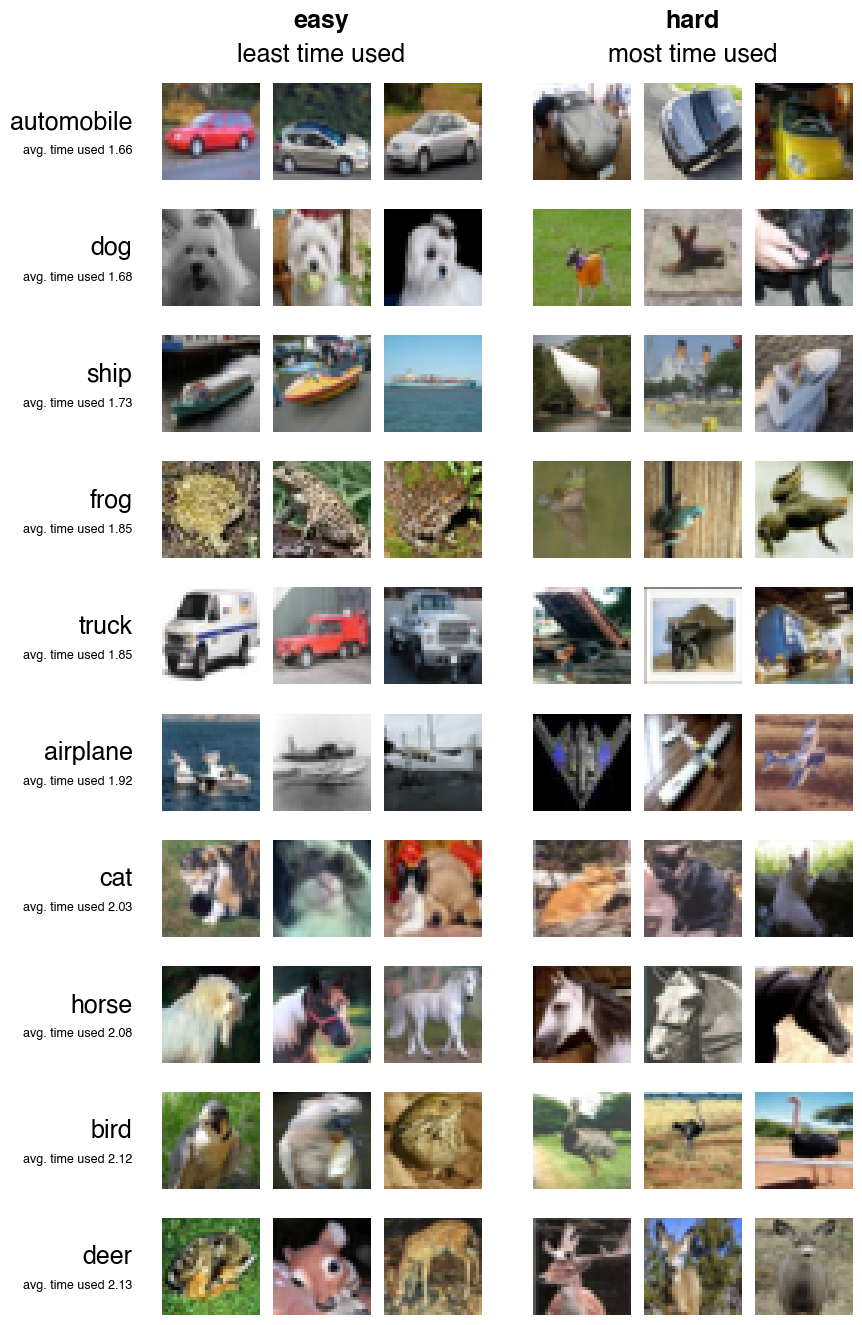

In [25]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

n_per_cat = 3
n_cats = len(CIFAR10_CATEGORIES)

cfg_base.dataset.occlusion_proportion = 0.0  # ensuring that we show original images without occlusion (in case overwrote later)
test_dataset = nn_bowl.utils.get_dataloaders(cfg_base)["test"].dataset

# helvetica
plt.rcParams["font.family"] = "Helvetica"

size_factor = 20
fig, axes = plt.subplots(
    n_cats, n_per_cat * 2 + 1,
    # figsize=(n_per_cat * 2 + 1, n_cats * 1.3),
    figsize=(0.45 * size_factor, 0.8 * size_factor),
    gridspec_kw={'wspace': 0.08, 'hspace': 0.3},
    width_ratios=[1]* n_per_cat + [0.3] + [1]* n_per_cat
)

for cat_idx in range(n_cats):
    axes[cat_idx, n_per_cat].axis('off')

# Compute mean difficulty per category and sort
cat_difficulty_order = (
    difficulty_df.groupby("cifar10_category")["time_used"]
    .mean()
    .sort_values()
)
cifar10_cats_sorted = cat_difficulty_order.index.tolist()

# for cat_idx, cat in enumerate(CIFAR10_CATEGORIES):
for cat_idx, cat in enumerate(cifar10_cats_sorted):
    cat_mask = difficulty_df["cifar10_category"] == cat
    cat_difficulty = difficulty_df[cat_mask].groupby("dataset_idx")["time_used"].mean()
    easiest_idx = cat_difficulty.nsmallest(n_per_cat).index.tolist()
    hardest_idx = cat_difficulty.nlargest(n_per_cat).index.tolist()

    for i, idx in enumerate(easiest_idx):
        img = nn_bowl.utils.denormalize_cifar10(test_dataset[int(idx)]["img"]).permute(1, 2, 0).numpy()
        axes[cat_idx, i].imshow(img, interpolation='nearest')
        axes[cat_idx, i].axis('off')


    # Spacer column
    axes[cat_idx, 0].axis('on')
    # axes[cat_idx, 0].set_ylabel(cat, fontsize=10, rotation=90, labelpad=10)
    axes[cat_idx, 0].set_xticks([])
    axes[cat_idx, 0].set_yticks([])

    for spine in axes[cat_idx, 0].spines.values():
        spine.set_visible(False)

    for i, idx in enumerate(hardest_idx):
        img = nn_bowl.utils.denormalize_cifar10(test_dataset[int(idx)]["img"]).permute(1, 2, 0).numpy()
        axes[cat_idx, i + n_per_cat + 1].imshow(img, interpolation='nearest')
        axes[cat_idx, i + n_per_cat + 1].axis('off')

    # Category label
    # axes[cat_idx, 0].set_ylabel(cat, fontsize=cfg_base.plotting.font.size, rotation=0, labelpad=10, ha='right', va='center')
    axes[cat_idx, 0].text(
        -0.3, 0.6, cat,
        fontsize=cfg_base.plotting.font.size,
        rotation=0, ha='right', va='center',
        transform=axes[cat_idx, 0].transAxes,
    )
    avg_time = cat_difficulty_order[cat]
    axes[cat_idx, 0].text(
        -0.3, 0.3, f"avg. time used {avg_time:.2f}",
        fontsize=cfg_base.plotting.font.size // 2,
        rotation=0, ha='right', va='center',
        transform=axes[cat_idx, 0].transAxes,
    )
    axes[cat_idx, 0].yaxis.set_label_position("left")

axes[0, n_per_cat // 2].set_title("easy", fontsize=cfg_base.plotting.font.size, fontweight='bold', pad=40)
axes[0, n_per_cat + 1 + n_per_cat // 2].set_title("hard", fontsize=cfg_base.plotting.font.size, fontweight='bold', pad=40)
axes[0, n_per_cat // 2].text(0.5, 1.3, "least time used", fontsize=cfg_base.plotting.font.size, ha='center', va='center', transform=axes[0, n_per_cat // 2].transAxes)
axes[0, n_per_cat + 1 + n_per_cat // 2].text(0.5, 1.3, "most time used", fontsize=cfg_base.plotting.font.size, ha='center', va='center', transform=axes[0, n_per_cat + 1 + n_per_cat // 2].transAxes)

plt.savefig(figures_dir / "time_example_images_by_time_difficulty_full.pdf", dpi=300, bbox_inches='tight')

1 extra bytes in post.stringData array
1 extra bytes in post.stringData array


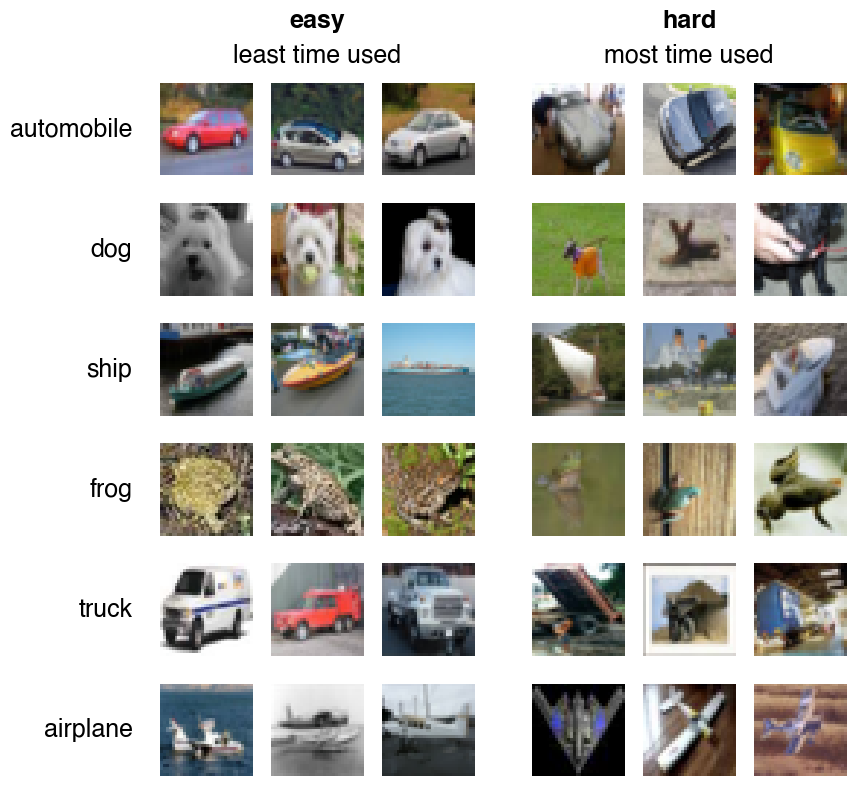

In [26]:
n_per_cat = 3
n_show_cats = 6
cfg_base.dataset.occlusion_proportion = 0.0  # ensuring that we show original images without occlusion (in case overwrote later)
test_dataset = nn_bowl.utils.get_dataloaders(cfg_base)["test"].dataset
plt.rcParams["font.family"] = "Helvetica"
size_factor = 20

cat_difficulty_order = (
    difficulty_df.groupby("cifar10_category")["time_used"]
    .mean()
    .sort_values()
)
cifar10_cats_sorted = cat_difficulty_order.index.tolist()[:n_show_cats]

fig, axes = plt.subplots(
    n_show_cats, n_per_cat * 2 + 1,
    figsize=(0.45 * size_factor, 0.45 * size_factor),
    gridspec_kw={'wspace': 0.08, 'hspace': 0.3},
    width_ratios=[1] * n_per_cat + [0.3] + [1] * n_per_cat,
)

for cat_idx, cat in enumerate(cifar10_cats_sorted):
    cat_mask = difficulty_df["cifar10_category"] == cat
    cat_difficulty = difficulty_df[cat_mask].groupby("dataset_idx")["time_used"].mean()
    easiest_idx = cat_difficulty.nsmallest(n_per_cat).index.tolist()
    hardest_idx = cat_difficulty.nlargest(n_per_cat).index.tolist()

    for i, idx in enumerate(easiest_idx):
        img = nn_bowl.utils.denormalize_cifar10(test_dataset[int(idx)]["img"]).permute(1, 2, 0).numpy()
        axes[cat_idx, i].imshow(img, interpolation='nearest')
        axes[cat_idx, i].axis('off')

    # spacer
    axes[cat_idx, n_per_cat].axis('off')

    for i, idx in enumerate(hardest_idx):
        img = nn_bowl.utils.denormalize_cifar10(test_dataset[int(idx)]["img"]).permute(1, 2, 0).numpy()
        axes[cat_idx, i + n_per_cat + 1].imshow(img, interpolation='nearest')
        axes[cat_idx, i + n_per_cat + 1].axis('off')

    # category label
    axes[cat_idx, 0].axis('on')
    axes[cat_idx, 0].set_xticks([])
    axes[cat_idx, 0].set_yticks([])
    for spine in axes[cat_idx, 0].spines.values():
        spine.set_visible(False)
    axes[cat_idx, 0].text(
        -0.3, 0.5, cat,
        fontsize=cfg_base.plotting.font.size,
        ha='right', va='center',
        transform=axes[cat_idx, 0].transAxes,
    )
    avg_time = cat_difficulty_order[cat]
    # axes[cat_idx, 0].text(
    #     -0.3, 0.35, f"avg. time used {avg_time:.2f}",
    #     fontsize=cfg_base.plotting.font.size // 1.5,
    #     ha='right', va='center',
    #     transform=axes[cat_idx, 0].transAxes,
    # )

axes[0, n_per_cat // 2].set_title("easy", fontsize=cfg_base.plotting.font.size, fontweight='bold', pad=40)
axes[0, n_per_cat + 1 + n_per_cat // 2].set_title("hard", fontsize=cfg_base.plotting.font.size, fontweight='bold', pad=40)
axes[0, n_per_cat // 2].text(0.5, 1.3, "least time used", fontsize=cfg_base.plotting.font.size, ha='center', va='center', transform=axes[0, n_per_cat // 2].transAxes)
axes[0, n_per_cat + 1 + n_per_cat // 2].text(0.5, 1.3, "most time used", fontsize=cfg_base.plotting.font.size, ha='center', va='center', transform=axes[0, n_per_cat + 1 + n_per_cat // 2].transAxes)

plt.savefig(figures_dir / "time_example_images_by_time_difficulty.pdf", dpi=300, bbox_inches='tight')

In [27]:
occlusion_df = nn_bowl.utils.get_occlusion_df(cfg_base, model_df[model_df["model.time_selection.scheme"] == "adaptive"])
occlusion_df

  0%|          | 0/110 [00:00<?, ?it/s]

100%|██████████| 110/110 [00:57<00:00,  1.92it/s]


,model_name,model.time_selection.scheme,costs.time.lam,instance,occlusion_proportion,dataset_idx,label,pred,correct,confidence,entropy,time_used
0,scheme=adaptive_lam=0.0_i0,adaptive,0.0,0,0.0,0,3,3,1,0.972092,0.182821,4.895110
1,scheme=adaptive_lam=0.0_i0,adaptive,0.0,0,0.0,1,8,8,1,0.950690,0.226298,4.887924
2,scheme=adaptive_lam=0.0_i0,adaptive,0.0,0,0.0,2,8,8,1,0.990533,0.073725,4.885360
3,scheme=adaptive_lam=0.0_i0,adaptive,0.0,0,0.0,3,0,8,0,0.025518,0.187294,4.880078
4,scheme=adaptive_lam=0.0_i0,adaptive,0.0,0,0.0,4,6,6,1,0.989200,0.079432,4.879770
...,...,...,...,...,...,...,...,...,...,...,...,...
5499995,scheme=adaptive_lam=1.0_i9,adaptive,1.0,9,0.2,9995,8,0,0,0.037062,0.918138,1.103488
5499996,scheme=adaptive_lam=1.0_i9,adaptive,1.0,9,0.2,9996,3,3,1,0.560835,0.964327,1.103502
5499997,scheme=adaptive_lam=1.0_i9,adaptive,1.0,9,0.2,9997,5,5,1,0.514806,0.740623,1.103757
5499998,scheme=adaptive_lam=1.0_i9,adaptive,1.0,9,0.2,9998,1,1,1,0.767737,0.777334,1.103481


In [28]:
occlusion_agg_df = occlusion_df.groupby(["occlusion_proportion", "costs.time.lam", "instance"], as_index=False).agg(
    accuracy=("correct", "mean"),
    time_used=("time_used", "mean"),
)
sel = occlusion_agg_df["costs.time.lam"] == cfg_base.analysis.occlusion_lam_time # selecting the intermediate, most adaptive regime
occlusion_agg_df = occlusion_agg_df[sel]
occlusion_agg_df

,occlusion_proportion,costs.time.lam,instance,accuracy,time_used
20,0.00,0.2,0,0.8723,2.741561
21,0.00,0.2,1,0.8602,2.758553
22,0.00,0.2,2,0.8737,2.681414
23,0.00,0.2,3,0.8707,2.798840
24,0.00,0.2,4,0.8761,2.760015
25,0.00,0.2,5,0.8737,2.693674
26,0.00,0.2,6,0.8760,2.805504
27,0.00,0.2,7,0.8756,2.688426
28,0.00,0.2,8,0.8711,2.695800
29,0.00,0.2,9,0.8718,2.635633


In [29]:
n = cfg_base.experiment.n_instances
multiplier = t.ppf(0.975, df=n - 1)
color = cfg_base.plotting.time

agg = occlusion_agg_df.groupby("occlusion_proportion")["time_used"].agg(["mean", "std"]).reset_index()
sems = multiplier * agg["std"] / np.sqrt(n)

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=agg["occlusion_proportion"],
    y=agg["mean"],
    error_y=dict(type="data", array=sems, visible=True),
    mode="lines+markers",
    marker=dict(size=7, color=color),
    line=dict(color=color, width=2),
    showlegend=False,
))

fig.update_xaxes(title_text="occlusion at test time", title_standoff=60, tickvals=[0.0, 0.05, 0.1, 0.15, 0.2], ticktext=["0%", "5%", "10%", "15%", "20%"])
fig.update_yaxes(title_text="time used", title_standoff=7)
fig.update_layout(
    width=WIDTH * 0.25,
    height=WIDTH * 0.25,
    margin=dict(l=55, r=10, t=20, b=110),
)
fig.add_annotation(
    x=0.65, y=0.3, xref='paper', yref='paper',
    text=f"λ<sub>time</sub> = {cfg_base.analysis.occlusion_lam_time}",
    showarrow=False, font=dict(size=cfg_base.plotting.font.size, color=color),
    xanchor='center', yanchor='top',
)
fig.show()
nn_bowl.utils.save_figure(fig, figures_dir, "time_occlusion_time_used", scale=4)

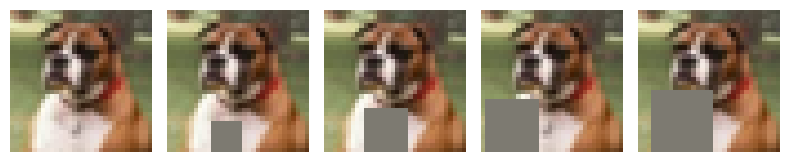

In [30]:
occlusion_proportions = cfg_base.analysis.occlusion_proportions

datasets = {}
for occlusion_proportion in occlusion_proportions:
    cfg_base.dataset.occlusion_proportion = occlusion_proportion
    dataloader = nn_bowl.utils.get_dataloaders(cfg_base)["test"]
    datasets[occlusion_proportion] = dataloader.dataset

example_index = 3931

fig, axes = plt.subplots(1, len(occlusion_proportions), figsize=(1.6 * len(occlusion_proportions), 2))
for i, occlusion_proportion in enumerate(occlusion_proportions):
    img_normalized = datasets[occlusion_proportion][example_index]["img"]
    img = nn_bowl.utils.denormalize_cifar10(img_normalized).permute(1, 2, 0).numpy()
    axes[i].imshow(np.clip(img, 0, 1), interpolation='nearest')
    # axes[i].set_title(f"{occlusion_proportion}", fontsize=13)
    axes[i].axis('off')
# plt.suptitle("occlusion proportion", fontsize=15)
plt.tight_layout()
plt.savefig(figures_dir / "occlusion_examples.pdf", dpi=300, bbox_inches='tight')
# plt.show()